In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
turbines = pd.read_parquet("/Users/zsquirrel/Downloads/WindChasersData/alta10_turbine_data_grouped.parquet")

In [8]:
turbines.head()

turbine                  wtg150                                    \
variable            air_density blade_position_2 blade_position_3   
utc_time                                                            
2026-01-01 08:00:00    1.092081        -1.056245        -0.643520   
2026-01-01 08:10:00    0.800856        -1.077751        -0.680390   
2026-01-01 08:20:00    1.089478        -0.445800        -0.039797   
2026-01-01 08:30:00    0.800936        -1.205972        -0.786801   
2026-01-01 08:40:00    1.090836        -1.205672        -0.786363   

turbine                                                                  \
variable            blade_setpoint_position_1 blade_setpoint_position_2   
utc_time                                                                  
2026-01-01 08:00:00                  2.307242                 -0.892182   
2026-01-01 08:10:00                  2.354385                 -0.845038   
2026-01-01 08:20:00                  2.813232                 -0.386191   
2026-01-01 08:30:00                       NaN                       NaN   
2026-01-01 08:40:00                       NaN                       NaN   

turbine                                                                        \
variable            blade_setpoint_position_3 nacelle_position real_power_a_c   
utc_time                                                                        
2026-01-01 08:00:00                 -0.471435       118.785714      672.60510   
2026-01-01 08:10:00                 -0.424893       117.066667      541.30096   
2026-01-01 08:20:00                  0.032674       118.812500      237.94884   
2026-01-01 08:30:00                       NaN              NaN      503.22354   
2026-01-01 08:40:00                       NaN       130.000000      444.42767   

turbine                                                   ...  \
variable            real_power_a_c_2 temperature_ambient  ...   
utc_time                                                  ...   
2026-01-01 08:00:00       670.286714            8.299405  ...   
2026-01-01 08:10:00       542.747853            8.573889  ...   
2026-01-01 08:20:00       239.185173            8.972823  ...   
2026-01-01 08:30:00       504.556470            8.531316  ...   
2026-01-01 08:40:00       444.157211            8.621079  ...   

turbine                       wtg197                                  \
variable            nacelle_position real_power_a_c real_power_a_c_2   
utc_time                                                               
2026-01-01 08:00:00        62.500000      1232.1998      1229.936331   
2026-01-01 08:10:00        59.000000       990.2687       990.641605   
2026-01-01 08:20:00        58.666667      1074.2076      1074.568828   
2026-01-01 08:30:00        67.333333      1108.8040      1108.957917   
2026-01-01 08:40:00        67.100000      1124.4481      1123.277779   

turbine                                                             \
variable            temperature_ambient temperature_ambient_merged   
utc_time                                                             
2026-01-01 08:00:00            6.258348                   6.258348   
2026-01-01 08:10:00            6.331188                   6.331188   
2026-01-01 08:20:00            6.456590                   6.456590   
2026-01-01 08:30:00            6.545990                   6.545990   
2026-01-01 08:40:00            6.563307                   6.563307   

turbine                                                                       \
variable            theoretical_power wind_direction wind_direction_relative   
utc_time                                                                       
2026-01-01 08:00:00         1418.4381      54.739130               -6.454545   
2026-01-01 08:10:00          817.2081      52.763514               -5.510949   
2026-01-01 08:20:00         1234.4576      53.654930               -4.808824   
2026-01-01 08:30:00          843.8777      60.771812      

In [9]:
# Reshape wide to long
all_turbines = (
    turbines
    .stack(level="turbine", future_stack=True)
    .reset_index()
)

In [10]:
all_turbines.head()

variable,utc_time,turbine,air_density,blade_position_2,blade_position_3,blade_setpoint_position_1,blade_setpoint_position_2,blade_setpoint_position_3,nacelle_position,real_power_a_c,real_power_a_c_2,temperature_ambient,temperature_ambient_merged,theoretical_power,wind_direction,wind_direction_relative,wind_speed,wind_speed_2,blade_position_1
0,2026-01-01 08:00:00,wtg150,1.092081,-1.056245,-0.643520,2.307242,-0.892182,-0.471435,118.785714,672.60510,670.286714,8.299405,8.299405,746.68463,115.629870,-1.392857,6.906036,6.907681,NaN
1,2026-01-01 08:00:00,wtg151,1.087094,-0.925170,1.124203,0.856155,-0.676644,1.384543,113.500000,485.57794,485.492347,9.592089,9.592089,406.01855,116.709677,6.439716,5.730449,5.717620,0.614472
2,2026-01-01 08:00:00,wtg152,1.090355,0.200810,0.278822,NaN,NaN,NaN,259.600000,497.79605,496.384967,8.745550,8.745550,440.09213,252.291139,-5.909091,5.862610,5.836812,-0.481281
3,2026-01-01 08:00:00,wtg153,1.044950,0.342474,-0.278986,-0.027131,0.376825,-0.244748,291.230769,423.57132,422.188638,21.009600,21.009600,445.82935,283.955414,-6.215278,5.969328,5.951737,-0.059970
4,2026-01-01 08:00:00,wtg154,1.088453,1.907079,1.215503,-1.376194,1.938141,1.257423,140.000000,274.52768,274.276035,9.238713,9.238713,208.84138,139.118343,-4.608108,4.760764,4.757731,-1.428621


In [11]:
# Power diffs
all_turbines["power_diff_ac"] = (
    all_turbines["theoretical_power"]
    - all_turbines["real_power_a_c"]
)

all_turbines["power_diff_ac2"] = (
    all_turbines["theoretical_power"]
    - all_turbines["real_power_a_c_2"]
)

In [12]:
all_turbines[[
    "utc_time",
    "turbine",
    "theoretical_power",
    "real_power_a_c",
    "real_power_a_c_2",
    "power_diff_ac",
    "power_diff_ac2"
]].head()

variable,utc_time,turbine,theoretical_power,real_power_a_c,real_power_a_c_2,power_diff_ac,power_diff_ac2
0,2026-01-01 08:00:00,wtg150,746.68463,672.60510,670.286714,74.07953,76.397916
1,2026-01-01 08:00:00,wtg151,406.01855,485.57794,485.492347,-79.55939,-79.473797
2,2026-01-01 08:00:00,wtg152,440.09213,497.79605,496.384967,-57.70392,-56.292837
3,2026-01-01 08:00:00,wtg153,445.82935,423.57132,422.188638,22.25803,23.640712
4,2026-01-01 08:00:00,wtg154,208.84138,274.52768,274.276035,-65.68630,-65.434655


In [13]:
# Correlation Analysis ac power
all_turbines.corr(numeric_only=True)["power_diff_ac"].sort_values(
    key=abs,
    ascending=False
)

variable
power_diff_ac                 1.000000
power_diff_ac2                0.804303
wind_speed                    0.471397
wind_speed_2                  0.469884
theoretical_power             0.422204
blade_position_3              0.275962
blade_position_2              0.275475
blade_setpoint_position_2     0.250254
blade_setpoint_position_3     0.250038
blade_setpoint_position_1     0.249923
real_power_a_c_2             -0.190386
real_power_a_c               -0.186632
temperature_ambient          -0.144619
temperature_ambient_merged   -0.144196
blade_position_1              0.131119
wind_direction_relative      -0.023950
nacelle_position              0.019745
wind_direction                0.016120
air_density                   0.008514
Name: power_diff_ac, dtype: float64

In [14]:
# Correlation Analysis on ac2 power
all_turbines.corr(numeric_only=True)["power_diff_ac2"].sort_values(
    key=abs,
    ascending=False
)

variable
power_diff_ac2                1.000000
power_diff_ac                 0.804303
real_power_a_c               -0.389901
air_density                   0.380233
real_power_a_c_2             -0.375139
wind_speed_2                 -0.176951
wind_speed                   -0.175442
theoretical_power            -0.151688
blade_setpoint_position_1     0.078784
wind_direction               -0.074820
blade_setpoint_position_2     0.072173
nacelle_position             -0.070621
blade_setpoint_position_3     0.068120
blade_position_1              0.065294
blade_position_2              0.054386
blade_position_3              0.051184
temperature_ambient          -0.038739
temperature_ambient_merged   -0.037663
wind_direction_relative      -0.036883
Name: power_diff_ac2, dtype: float64

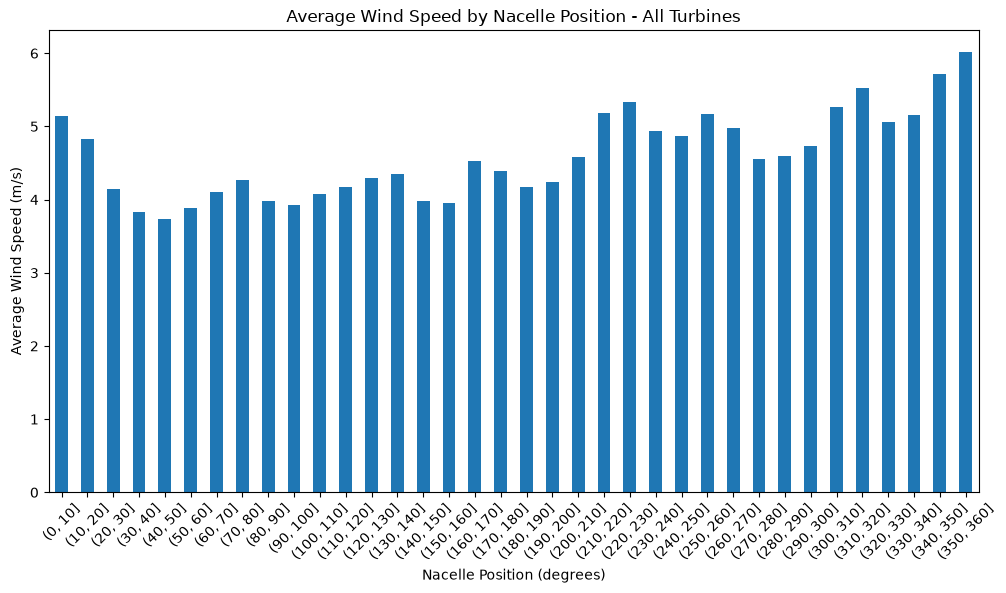

In [15]:
# Average windspeed by nacelle position
import matplotlib.pyplot as plt
import pandas as pd

plot_data = all_turbines[
    ["wind_speed", "nacelle_position"]
].dropna().copy()

plot_data["nacelle_bin"] = pd.cut(
    plot_data["nacelle_position"],
    bins=range(0, 361, 10)
)

bar_data = (
    plot_data
    .groupby("nacelle_bin", observed=True)["wind_speed"]
    .mean()
)

plt.figure(figsize=(12, 6))

bar_data.plot(kind="bar")

plt.xlabel("Nacelle Position (degrees)")
plt.ylabel("Average Wind Speed (m/s)")
plt.title("Average Wind Speed by Nacelle Position - All Turbines")
plt.xticks(rotation=45)

plt.show()

In [17]:
all_turbines["turbine"].unique()

<ArrowStringArray>
['wtg150', 'wtg151', 'wtg152', 'wtg153', 'wtg154', 'wtg155', 'wtg156',
 'wtg157', 'wtg158', 'wtg159', 'wtg161', 'wtg162', 'wtg163', 'wtg164',
 'wtg165', 'wtg166', 'wtg167', 'wtg168', 'wtg169', 'wtg170', 'wtg171',
 'wtg172', 'wtg173', 'wtg174', 'wtg175', 'wtg176', 'wtg177', 'wtg178',
 'wtg179', 'wtg180', 'wtg181', 'wtg182', 'wtg183', 'wtg184', 'wtg185',
 'wtg186', 'wtg187', 'wtg188', 'wtg189', 'wtg190', 'wtg191', 'wtg192',
 'wtg193', 'wtg194', 'wtg195', 'wtg196', 'wtg197']
Length: 47, dtype: str